# Exploración del FASTA

**Responsable:** Thomas

**Objetivo:** conocer el FASTA antes de cargarlo y registrar sus inconsistencias, sin modificar los datos. La exploración del CSV está en `00_exploracion_csv.ipynb` (Juan Arias).

Modelo de referencia: `../MODELO.md`

## 0. Configuración

Rutas a los datos. Los archivos deben estar en `data/`.

In [1]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO

FASTA = Path("../data/PanTEon_Database_v1.6.1.fasta")
CSV = Path("../data/PanTEon_Database_metadata_v1.6.1.csv")
RESULTADOS = Path("../resultados")

print("FASTA existe:", FASTA.exists(), "|", round(FASTA.stat().st_size / 1e6), "MB")

FASTA existe: True | 992 MB


## 1. Lectura del FASTA (una sola pasada)

Se recorre el archivo registro por registro, sin cargar las secuencias en memoria. De cada registro se separa el encabezado (`ID#CLASE/ORDEN/SUPERFAMILIA @Especie`) y se calculan los atributos: **longitud**, **contenido GC** (`(G+C)/(A+C+G+T)`) y **% de N**. Tarda unos minutos.

No se modifica nada: solo se mide.

In [3]:
# No guarda las secuencias en memoria: solo lo que se mide de cada una.
filas = []
caracteres = Counter()

for rec in SeqIO.parse(FASTA, "fasta"):
    header = rec.description          # encabezado completo, sin ">"
    seq = str(rec.seq)

    # Formato esperado: ID#CLASE/ORDEN/SUPERFAMILIA @Especie
    izq, especie = header.split("@", 1) if "@" in header else (header, "")
    pdb, clasif = izq.split("#", 1) if "#" in izq else (izq, "")
    niveles = [x for x in clasif.strip().split("/") if x] if clasif.strip() else []

    caracteres.update(seq)
    up = seq.upper()
    a, c, g, t, n = (up.count(b) for b in "ACGTN")
    validas = a + c + g + t

    filas.append({
        "pdb_id": pdb.strip(),
        "header_ok": "#" in header and "@" in header,
        "clasificacion": clasif.strip(),
        "n_niveles": len(niveles),
        "te_class": niveles[0] if len(niveles) > 0 else None,
        "te_order": niveles[1] if len(niveles) > 1 else None,
        "te_superfamily": niveles[2] if len(niveles) > 2 else None,
        "especie_raw": especie,
        "especie": " ".join(especie.split()),   # sin espacios sobrantes
        "length": len(seq),
        "gc": (g + c) / validas if validas else None,
        "n_pct": n / len(seq) if seq else None,
        "otros_chars": len(seq) - validas - n,  # IUPAC u otros
        "minusculas": seq != up,
    })

df = pd.DataFrame(filas)
print("Registros leídos:", len(df))
df.head()

Registros leídos: 239946


,pdb_id,header_ok,clasificacion,n_niveles,te_class,te_order,te_superfamily,especie_raw,especie,length,gc,n_pct,otros_chars,minusculas
0,PDB00000001,True,CLASSII/HELITRON/HELITRON,3,CLASSII,HELITRON,HELITRON,Halicephalobus mephisto,Halicephalobus mephisto,1991,0.315419,0.0,0,True
1,PDB00000002,True,CLASSII/HELITRON/HELITRON,3,CLASSII,HELITRON,HELITRON,Halicephalobus mephisto,Halicephalobus mephisto,1689,0.315571,0.0,0,True
2,PumCon-1.11,True,CLASSI/SINE/TRNA,3,CLASSI,SINE,TRNA,Puma concolor,Puma concolor,235,0.510638,0.0,0,False
3,PumCon-1.141,True,CLASSII/TIR/TC1MARINER,3,CLASSII,TIR,TC1MARINER,Puma concolor,Puma concolor,340,0.397059,0.0,0,False
4,PumCon-1.14,True,CLASSI/SINE/TRNA,3,CLASSI,SINE,TRNA,Puma concolor,Puma concolor,233,0.527897,0.0,0,False


## 2. Encabezados e identificadores

¿Todos los encabezados tienen `#` y `@`? ¿Los PDB tienen el formato esperado y son únicos?

In [4]:
print("Encabezados sin '#' o sin '@':", (~df.header_ok).sum())
print("PDB con formato distinto a PDB + 8 dígitos:",
      (~df.pdb_id.str.fullmatch(r"PDB\d{8}")).sum())
print("PDB duplicados:", df.pdb_id.duplicated().sum())
display(df[~df.header_ok | df.pdb_id.duplicated(keep=False)].head(20))

Encabezados sin '#' o sin '@': 0
PDB con formato distinto a PDB + 8 dígitos: 31600
PDB duplicados: 0


,pdb_id,header_ok,clasificacion,n_niveles,te_class,te_order,te_superfamily,especie_raw,especie,length,gc,n_pct,otros_chars,minusculas


## 3. Clasificación del TE

¿Todas tienen 3 niveles (Clase/Orden/Superfamilia)? ¿Qué valores hay en cada nivel? ¿Hay valores desconocidos?

In [5]:
print("Niveles de clasificación por registro:")
display(df.n_niveles.value_counts().sort_index())
display(df[df.n_niveles != 3][["pdb_id", "clasificacion"]].head(20))

print("Clases:")
display(df.te_class.value_counts(dropna=False))
print("Órdenes:")
display(df.te_order.value_counts(dropna=False))
print("Superfamilias distintas:", df.te_superfamily.nunique())
display(df.te_superfamily.value_counts(dropna=False).head(30))

# Valores sospechosos (desconocidos o vacíos) en cualquier nivel
sospechosos = df.clasificacion.str.contains(r"(?i)unknown|unclass|^na$|/na/|none|\?", regex=True)
print("Clasificaciones sospechosas:", sospechosos.sum())
display(df[sospechosos].clasificacion.value_counts().head(20))

Niveles de clasificación por registro:


n_niveles
3    239946
Name: count, dtype: int64

,pdb_id,clasificacion


Clases:


te_class
CLASSI     194774
CLASSII     45172
Name: count, dtype: int64

...

te_order
LTR           119368
LINE           68382
TIR            36471
HELITRON        5075
SINE            3634
MITE            3456
DIRS            2933
PLE              344
RETROPOSON       113
CRYPTON          112
MAVERICK          58
Name: count, dtype: int64

Superfamilias distintas: 66


te_superfamily
COPIA           50849
GYPSY           43963
L1              23821
ERV             12202
CR1             11234
L2              10962
TC1MARINER      10729
HAT             10648
TIR              5983
RTE              5143
HELITRON         5075
LARD             4588
TAD1             3854
MITE             3456
PIFHARBINGER     3010
CAULIMOVIRUS     2962
CMC              2352
MULE             2306
DIRS             2067
LINE             2066
BELPAO           1995
I                1990
REX-BABAR        1923
JOCKEY           1605
LTR              1499
LOA              1368
RTEX             1314
TRIM             1310
TRNA             1271
R1               1176
Name: count, dtype: int64

Clasificaciones sospechosas: 0


Series([], Name: count, dtype: int64)

## 4. Especies

Especies distintas, espacios sobrantes y una vista rápida del cruce con el CSV. La lista se guarda en `resultados/especies_fasta.csv` para Juan Arias.

In [6]:
print("Especies distintas en el FASTA:", df.especie.nunique())
print("Registros con espacios sobrantes en la especie:", (df.especie_raw != df.especie).sum())

conteo_especies = df.especie.value_counts().rename_axis("especie").reset_index(name="n_tes")
conteo_especies.to_csv(RESULTADOS / "especies_fasta.csv", index=False)   # para Juan Arias
print("Guardado resultados/especies_fasta.csv")
display(conteo_especies.head(10))
display(conteo_especies.tail(10))

# Vista rápida del cruce con el CSV (el análisis completo lo hace Juan Arias)
csv_especies = set(pd.read_csv(CSV, encoding="utf-8-sig")["Species"].astype(str).str.split().str.join(" ").str.lower())
fasta_especies = set(df.especie.str.lower())
print("Especies del FASTA que no están en el CSV:", len(fasta_especies - csv_especies))
print("Especies del CSV sin TEs en el FASTA:", len(csv_especies - fasta_especies))
print(sorted(fasta_especies - csv_especies)[:20])

Especies distintas en el FASTA: 2790
Registros con espacios sobrantes en la especie: 0
Guardado resultados/especies_fasta.csv


,especie,n_tes
0,Malus domestica,1627
1,Danio rerio,1352
2,Callithrix jacchus,1294
3,Homininae,1173
4,Nicotiana attenuata,1159
5,Colobus angolensis,1148
6,Chlorocebus sabaeus,1129
7,Geotrypetes seraphini,1115
8,Sitophilus oryzae,1103
9,Oryza sativa,1090


,especie,n_tes
2780,Scheffersomyces insectosa,1
2781,Aspergillus bombycis,1
2782,Scheffersomyces shehatae,1
2783,Heterodoassansia hygrophilae,1
2784,Zygotorulaspora mrakii,1
2785,Ustanciosporium gigantosporum,1
2786,Penicillium chermesinum,1
2787,Talaromyces rugulosus,1
2788,Lepidopterella palustris,1
2789,Aspergillus parafelis,1


Especies del FASTA que no están en el CSV: 4
Especies del CSV sin TEs en el FASTA: 4
['abrus pulchellus subsp. cantoniensis', 'beta vulgaris subsp. vulgaris', 'coccomyxa sp. obi', 'marchantia polymorpha subsp. montivagans']


## 5. Longitudes

Define cuánto conviene el diccionario disperso para los k-mers y si hay secuencias demasiado cortas.

count    239946.0
mean       4017.2
std        2751.3
min          81.0
5%          312.0
25%        1463.0
50%        4259.0
75%        5656.0
95%        8815.0
max       19926.0
Name: length, dtype: float64

Secuencias vacías: 0
Secuencias con longitud < 6 (sin 6-mers): 0


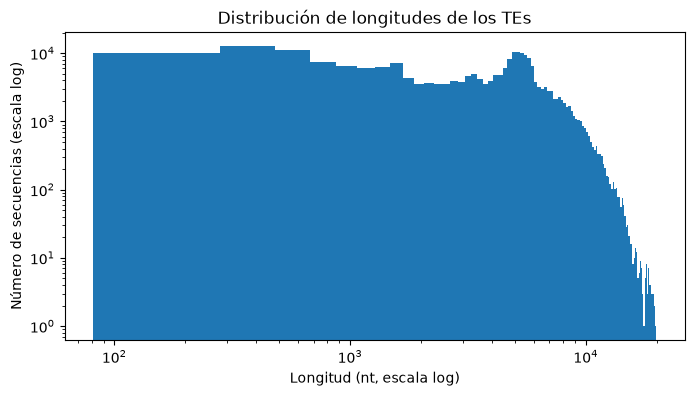

In [7]:
display(df.length.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
print("Secuencias vacías:", (df.length == 0).sum())
print("Secuencias con longitud < 6 (sin 6-mers):", (df.length < 6).sum())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df.length[df.length > 0], bins=100, log=True)
ax.set_xscale("log")
ax.set_xlabel("Longitud (nt, escala log)")
ax.set_ylabel("Número de secuencias (escala log)")
ax.set_title("Distribución de longitudes de los TEs")
plt.show()

## 6. Caracteres

¿Solo A, C, G, T y N? ¿Hay minúsculas u otros códigos IUPAC (R, Y, K...)?

In [8]:
print("Caracteres presentes y cuántas veces aparecen:")
display(pd.Series(caracteres).sort_values(ascending=False))
print("Secuencias con minúsculas:", df.minusculas.sum())
print("Secuencias con N:", (df.n_pct > 0).sum())
print("Secuencias con otros caracteres (no ACGTN):", (df.otros_chars > 0).sum())
display(df[df.n_pct > 0].n_pct.describe().round(4))

Caracteres presentes y cuántas veces aparecen:


a    263436503
t    259906800
g    201189924
c    185450715
A     15586362
T     13692487
G     11336386
C     11155077
n      1670546
N       476615
dtype: int64

Secuencias con minúsculas: 208354
Secuencias con N: 54837
Secuencias con otros caracteres (no ACGTN): 0


count    54837.0000
mean         0.0166
std          0.0201
min          0.0001
25%          0.0033
50%          0.0091
75%          0.0217
max          0.5006
Name: n_pct, dtype: float64

## 7. Atributos calculados (GC y % de N)

In [9]:
display(df[["length", "gc", "n_pct"]].describe().round(4))
display(df.groupby("te_class")[["length", "gc"]].mean().round(3))

,length,gc,n_pct
count,239946.0000,239946.0000,239946.0000
mean,4017.1598,0.4319,0.0038
std,2751.3267,0.0762,0.0119
min,81.0000,0.1121,0.0000
25%,1463.0000,0.3813,0.0000
50%,4259.0000,0.4230,0.0000
75%,5656.0000,0.4775,0.0000
max,19926.0000,0.8039,0.5006


,length,gc
te_class,,
CLASSI,4453.147,0.437
CLASSII,2137.255,0.410


## 8. Resumen de inconsistencias

Se guarda en `resultados/inconsistencias_fasta.csv`. Debajo, anotar la **decisión** para cada problema: va directo al artículo.

In [10]:
resumen = pd.DataFrame([
    ("Encabezados sin '#' o '@'", (~df.header_ok).sum()),
    ("PDB con formato inválido", (~df.pdb_id.str.fullmatch(r"PDB\d{8}")).sum()),
    ("PDB duplicados", df.pdb_id.duplicated().sum()),
    ("Clasificación con niveles distintos de 3", (df.n_niveles != 3).sum()),
    ("Clasificaciones sospechosas (unknown, NA...)", sospechosos.sum()),
    ("Registros con espacios sobrantes en la especie", (df.especie_raw != df.especie).sum()),
    ("Especies del FASTA sin metadatos en el CSV", len(fasta_especies - csv_especies)),
    ("Secuencias vacías", (df.length == 0).sum()),
    ("Secuencias de longitud < 6", (df.length < 6).sum()),
    ("Secuencias con minúsculas", df.minusculas.sum()),
    ("Secuencias con N", (df.n_pct > 0).sum()),
    ("Secuencias con caracteres distintos de ACGTN", (df.otros_chars > 0).sum()),
], columns=["Problema", "Casos"])
resumen.to_csv(RESULTADOS / "inconsistencias_fasta.csv", index=False)
resumen

,Problema,Casos
0,Encabezados sin '#' o '@',0
1,PDB con formato inválido,31600
2,PDB duplicados,0
3,Clasificación con niveles distintos de 3,0
4,"Clasificaciones sospechosas (unknown, NA...)",0
5,Registros con espacios sobrantes en la especie,0
6,Especies del FASTA sin metadatos en el CSV,4
7,Secuencias vacías,0
8,Secuencias de longitud < 6,0
9,Secuencias con minúsculas,208354


## 9. Resolver dudas de la exploración

1. Resolver la duda de los 31.600 PDB con formato distinto
La exploracón nos mostró que no siguen el patrón de PBD + 8 dígitos, pero tampoco dijo cómo son. Igualmente es algo que necesitamos saber porque 
- Para el $jsonSchema de tes: si exigimos PDB\d{8}, MongoDB va a rechazar esos 31.600 TEs cuando los carguemos. La regla debe aceptar el formato real.
- Tenemos que describir el formato del identificador y esta inconsistencia.
- No queremos modificarlos por eror, el PDB es el identificador original y se guarda tal cual; solo queremos entenderlo.

In [11]:
malos = df[~df.pdb_id.str.fullmatch(r"PDB\d{8}")]
print(malos.pdb_id.str.len().value_counts())
display(malos.pdb_id.sample(10, random_state=1))

igual_al_orden = df[df.te_superfamily == df.te_order]
display(igual_al_orden.clasificacion.value_counts())

pdb_id
12    6520
11    5339
9     3544
13    3378
8     3066
10    2816
18    1233
7     1225
14     783
6      585
15     373
16     344
5      295
21     262
30     252
17     247
22     195
31     158
24     152
23     135
25     128
19     114
20      95
26      91
27      72
28      67
4       65
29      46
3       16
2        3
32       1
Name: count, dtype: int64


37140          LTR105_Mam_11
66097              MER127_26
22344            CapPil-5.23
57736     TE0458_SO2_FAM1447
13654                LTR65_4
115227             UCON78_24
9583                MER58B_2
111275             UCON51_18
9756            Charlie32a_2
15997          Charlie14a_15
Name: pdb_id, dtype: str

clasificacion
CLASSII/TIR/TIR                 5983
CLASSII/HELITRON/HELITRON       5075
CLASSII/MITE/MITE               3456
CLASSI/DIRS/DIRS                2067
CLASSI/LINE/LINE                2066
CLASSI/LTR/LTR                  1499
CLASSI/SINE/SINE                 771
CLASSI/PLE/PLE                   344
CLASSI/RETROPOSON/RETROPOSON     113
CLASSII/CRYPTON/CRYPTON          112
CLASSII/MAVERICK/MAVERICK         58
Name: count, dtype: int64

In [12]:
csv = pd.read_csv(CSV, encoding="utf-8-sig")
fuente_por_especie = dict(zip(csv.Species.str.split().str.join(" ").str.lower(), csv.Source))
fuente = df.especie.str.lower().map(fuente_por_especie)
pd.crosstab(df.pdb_id.str.fullmatch(r"PDB\d{8}").rename("formato_PDB"), fuente)

especie,Dfam,RM2+MCH
formato_PDB,,
False,31592,8
True,0,207813


La primera tabla muestra los 8 TEs de especies RM2+MCH cuyo identificador no tiene formato PDB. Son las únicas excepciones a la regla de que las bibliotecas RM2+MCH usan identificadores PDB y las de Dfam conservan sus nombres originales, así que conviene revisarlas.

La segunda tabla muestra cuántos TEs tiene cada una de las 4 especies del FASTA que no cruzan con el CSV, para dimensionar cuántos registros se quedarían sin taxonomía si no se resuelve el cruce.

In [13]:
es_pdb = df.pdb_id.str.fullmatch(r"PDB\d{8}")
display(df[~es_pdb & (fuente == "RM2+MCH")][["pdb_id", "especie", "clasificacion"]])
display(df[fuente.isna()].especie.value_counts())

,pdb_id,especie,clasificacion
69805,Chlamys-2_cRei,Chlamydomonas reinhardtii,CLASSI/PLE/PLE
69806,Chlamys-5b_cRei,Chlamydomonas reinhardtii,CLASSI/PLE/PLE
69807,Chlamys-7_cRei,Chlamydomonas reinhardtii,CLASSI/PLE/PLE
69808,Chlamys-N4_cRei,Chlamydomonas reinhardtii,CLASSI/PLE/PLE
69809,Chlamys-N6_cRei,Chlamydomonas reinhardtii,CLASSI/PLE/PLE
101711,Chlamys-10b_cRei,Chlamydomonas reinhardtii,CLASSI/LINE/LINE
101966,Chlamys-10c_cRei,Chlamydomonas reinhardtii,CLASSI/LINE/LINE
102221,Chlamys-N2a_cRei,Chlamydomonas reinhardtii,CLASSI/LINE/LINE


especie
Beta vulgaris subsp. vulgaris               296
Abrus pulchellus subsp. cantoniensis        178
Marchantia polymorpha subsp. montivagans     48
Coccomyxa sp. obi                            11
Name: count, dtype: int64

## 10. Decisiones

| Problema | Casos | Decisión | Justificación |
|---|---|---|---|
| Identificadores sin formato `PDB` + 8 dígitos | 31.600 (31.592 de especies Dfam y 8 de Repbase, *C. reinhardtii*) | Se guardan sin modificar en `pdb_id`. Se mantiene el índice único y el `$jsonSchema` solo exige un texto no vacío. | Son los nombres originales de las bibliotecas curadas (Dfam, Repbase); las generadas con RM2+MCH usan `PDB`. No hay duplicados. |
| Superfamilia igual al orden | 21.544 (10.319 en TIR, LINE, LTR y SINE) | Se cargan tal como vienen. Los 10.319 se tratan como TEs clasificados solo hasta orden en el control de calidad. | En HELITRON, CRYPTON, MAVERICK y PLE el orden tiene una única superfamilia del mismo nombre (Wicker et al., 2007); en TIR, LINE, LTR y SINE indica que no se resolvió la superfamilia. |
| Secuencias con minúsculas | 208.354 (87 %) | Se conserva la secuencia original. El GC y los k-mers se calculan sobre la secuencia en mayúsculas. | La minúscula no cambia el nucleótido; contar sin distinguirla evita que `a` y `A` se cuenten por separado. |
| Secuencias con N | 54.837 (23 %; mediana 0,9 % de N) | Se conservan. La N se excluye del denominador del GC y se omiten las ventanas de k-mers que la contienen (`valid_windows`). | La N es un nucleótido desconocido; descartar esas secuencias perdería datos válidos. |
| Especies que no cruzan con el CSV | 4 especies, 533 TEs | Se normalizan los nombres quitando puntos, espacios sobrantes y mayúsculas. | Solo difieren en `subsp.`/`sp.`; su `TE_count` en el CSV coincide con el FASTA. Tras normalizar cruzan las 2.790. |
| "Homininae" registrada como especie | 1 grupo, 1.173 TEs | Se carga con `is_species: false`. | Es una subfamilia, no una especie. El CSV la marca en `Notes` como "Dfam no especie", igual que las demás entradas que no son especies; sus TEs se conservan. |
| Taxonomía inconsistente de *Beta vulgaris* en el CSV | 2 registros | Se cargan tal como vienen y se documentan. | *Beta vulgaris* figura en la familia Amaranthaceae (con clase vacía) y *B. vulgaris* subsp. *vulgaris* en Chenopodiaceae. Chenopodiaceae es un nombre antiguo, hoy incluido en Amaranthaceae según la clasificación APG, así que es un problema de nomenclatura desactualizada, no un error de especie. Corregirlo a mano implicaría modificar datos de la fuente. Es uno de los 10 casos de inconsistencia por género documentados en `resultados/reporte_calidad_csv.md`. ||

Sin problemas: no hay encabezados mal formados, identificadores duplicados, clasificaciones incompletas, caracteres distintos de A, C, G, T y N, ni secuencias de longitud menor que 6.